# EDA: що з даними (перед Part 1, CNN)

Звіт зібрано з `scripts/eda.py` (наявні фігури й таблиці) + нові перевірки: доменний зсув між телефонами, сигнал у простих статистиках зображення, найважчі зразки за OOF усіх наявних експериментів. Усі числа нижче рахуються в клітинках.

**Головне**
- **Даних дуже мало:** 24 ґрунти / 127 фото, але лише **16 незалежних сімейств** кривих. Фото одного зразка — це той самий ґрунт, тож ефективний N ≈ 16–24.
- **Масштаб — пастка №1:** train-фото збережені зменшеними (~4.6 px/mm), test — повнорозмірні (13.9 / 19.5 px/mm). Помилка масштабу 2× коштує ~30 EMD, тобто стільки ж, скільки оракул класу.
- **~30 % маси (медіана) дрібніше за 1 піксель** на робочих 4.5 px/mm. Пил і глину видно лише як колір/текстуру, а не як окремі зерна; висушені дрібні ґрунти на фото виглядають як грудки-агрегати.
- **Телефон змінює картинку сильніше, ніж ґрунт:** у Samsung фото розмиті (gradient ×0.68) і насиченіші за кольором (×1.5); test (iPhone) майже сірий, а iPhone 16 різкіший за будь-яке train-фото. Колір — це здебільшого «підпис» девайса.
- **Сигнал є, і він простий:** 4 текстурні числа + ridge дають CV **44.0**, тобто рівень заморожених ResNet-50 (T1 43.5) і fine-tuned ResNet-18 (C1 42.9). Колір сам по собі — 59.9.
- **Помилки моделей визначаються даними, а не архітектурою:** кореляція по зразках між експериментами 0.92. Гравій усі моделі передбачають добре (~10–25), а fine/sand погано (50–100); **H038 схожий на помилку мітки:** на фото дрібний ґрунт майже без каменів, а мітка — 53 % гравію (~115 EMD у всіх моделей).
- **Test візуально зміщений у бік піску/дрібних ґрунтів** (7 з 10 зразків, усі iPhone 16), тобто саме туди, де моделі найслабші.

In [1]:
import sys, tempfile, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Show, display
from scipy.ndimage import gaussian_filter, uniform_filter
from scipy.stats import spearmanr
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from soilgsd.config import ROOT, load_config, resolve
from soilgsd.data import SIEVES_MM, TARGET_COLS, load_labels, load_photo_index
from soilgsd.folds import iter_folds
from soilgsd.metric import LOG_WIDTHS, d_value, emd_parts, emd_per_sample, repair_cummax
from soilgsd.tiles import load_photo, load_soil_boxes, tile_cache

sys.path.insert(0, str(ROOT / "scripts"))
import eda  # figures and tables of scripts/eda.py are reused as is

warnings.filterwarnings("ignore")


def show(fig=None, path=None, width=1000):
    """Photo-heavy figures as JPEG so the notebook stays small."""
    import io
    from PIL import Image as PILImage
    buf = io.BytesIO()
    if fig is not None:
        fig.savefig(buf, format="jpeg", dpi=100, bbox_inches="tight", pil_kwargs={"quality": 85}); plt.close(fig)
    else:
        PILImage.open(path).convert("RGB").save(buf, format="jpeg", quality=85)
    display(Show(buf.getvalue(), format="jpeg", width=width))

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
eda.OUT = Path(tempfile.mkdtemp())  # scripts/eda.py figures go to a temp dir, reports/eda stays untouched

cfg = load_config()
labels = load_labels(cfg)
index = load_photo_index(cfg)
boxes = load_soil_boxes(cfg, index)
folds = pd.read_csv(resolve(cfg["cv"]["folds_file"]))
Y = labels.set_index("sample_id")[TARGET_COLS].astype(float)
cls = folds.drop_duplicates("sample_id").set_index("sample_id")["d50_class"].loc[Y.index]
fam = folds.drop_duplicates("sample_id").set_index("sample_id")["family"].loc[Y.index]
D50 = pd.Series(d_value(Y.to_numpy(), 50), index=Y.index)
ORDER = D50.sort_values().index  # samples from finest to coarsest everywhere below
CLASS_COLORS = eda.CLASS_COLORS
DEV_COLORS = {"Motorola Edge": "#1f77b4", "Samsung A52": "#ff7f0e", "Motorola Edge 60 Fusion": "#2ca02c",
              "iPhone 14": "#d62728", "iPhone 16": "#9467bd"}
WORK_PPM = 4.5
print(f"train: {len(Y)} samples, {(index.split == 'train').sum()} photos | "
      f"test: {index[index.split == 'test'].sample_id.nunique()} samples, {(index.split == 'test').sum()} photos")

train: 24 samples, 127 photos | test: 10 samples, 35 photos


## 1. Що є в даних
Train: 3 телефони, і майже кожен зразок знятий двома (Motorola + Samsung), тож девайс не корелює з міткою. Test знятий **іншими** телефонами (iPhone 14/16). Train-фото лежать у ~1600 px (stored_scale 0.4 / 0.17 від нативного розміру), тому реальний px/mm у train ≈ 4.6, а не 11.5 / 26.3 з `ppm_updated.csv`.

In [2]:
inv = (index.groupby(["split", "device"])
       .agg(photos=("path", "size"), samples=("sample_id", "nunique"),
            stored_px=("width", lambda s: f"{max(s.max(), index.loc[s.index, 'height'].max())}"),
            native_ppm=("ppm_native", "first"), stored_scale=("stored_scale", "first"),
            effective_ppm=("ppm", "first"), field_mm=("field_w_mm", "mean")))
pps = index.groupby(["split", "sample_id"]).size().groupby("split").agg(["min", "median", "max"])
combo = (index[index.split == "train"].groupby("sample_id")["device"]
         .agg(lambda s: " + ".join(sorted(set(s)))).value_counts().rename("train samples"))
display(inv.round(2), pps.rename(columns=lambda c: f"photos/sample {c}"), combo.to_frame())

photos  samples stored_px  native_ppm  \
split device                                                           
test  iPhone 14                    14        3      4032       13.94   
      iPhone 16                    21        7      5712       19.52   
train Motorola Edge                69       22      1600       11.49   
      Motorola Edge 60 Fusion       3        1      4096       12.46   
      Samsung A52                  55       22      1599       26.33   

                               stored_scale  effective_ppm  field_mm  
split device                                                          
test  iPhone 14                        1.00          13.94     289.2  
      iPhone 16                        1.00          19.52     292.5  
train Motorola Edge                    0.40           4.60     348.1  
      Motorola Edge 60 Fusion          1.00          12.46     328.6  
      Samsung A52                      0.17           4.55     351.2

,photos/sample min,photos/sample median,photos/sample max
split,,,
test,3,3.0,5
train,3,5.0,8


,train samples
device,
Motorola Edge + Samsung A52,21
Motorola Edge,1
Motorola Edge 60 Fusion,1
Samsung A52,1


## 2. Кадр
Поле зору у всіх девайсів ≈ 290–350 мм. У кадрі є лоток, рамка та лампа (у Samsung), і все це відрізняється між девайсами: потенційний shortcut. Тому тайли ріжемо лише всередині зеленої рамки.

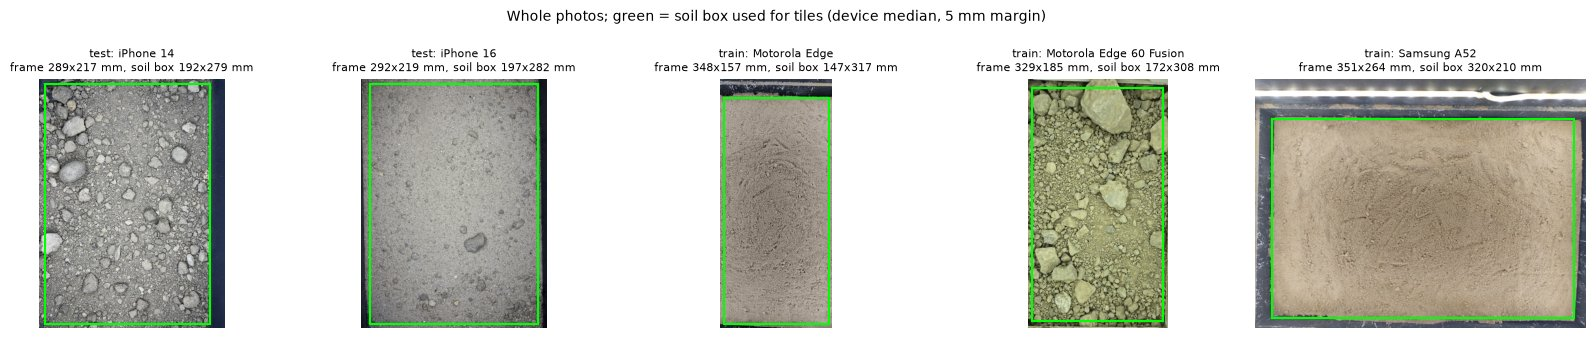

In [3]:
picks = index.sort_values("path").groupby("device").head(1).sort_values(["split", "device"])
fig, axes = plt.subplots(1, len(picks), figsize=(3.3 * len(picks), 3.4))
for ax, (i, r) in zip(axes, picks.iterrows()):
    im = load_photo(r["path"])
    s = 600 / max(im.size)
    ax.imshow(im.resize((round(im.width * s), round(im.height * s))))
    b = boxes.loc[i]
    ax.add_patch(plt.Rectangle((b.left * s, b.top * s), (b.right - b.left) * s, (b.bottom - b.top) * s,
                               fill=False, ec="lime", lw=1.5))
    ax.set_title(f"{r['split']}: {r['device']}\nframe {r.field_w_mm:.0f}x{r.field_h_mm:.0f} mm, "
                 f"soil box {b.soil_w_mm:.0f}x{b.soil_h_mm:.0f} mm", fontsize=8)
    ax.axis("off")
fig.suptitle("Whole photos; green = soil box used for tiles (device median, 5 mm margin)", fontsize=10)
plt.tight_layout(); show(fig, width=1100)

## 3. Фізичний масштаб
Верхній ряд — однакові 60 мм з кожного девайсу; нижній — однакова кількість пікселів (так виглядає «наївний» пайплайн: тест-зерна стають у 3–4 рази більшими). У таблиці — скільки пікселів займає зерно: на 4.5 px/mm пісок < 0.2 мм менший за піксель, а розпізнавати зерна як об'єкти можна приблизно від 0.63 мм (≈3 px).

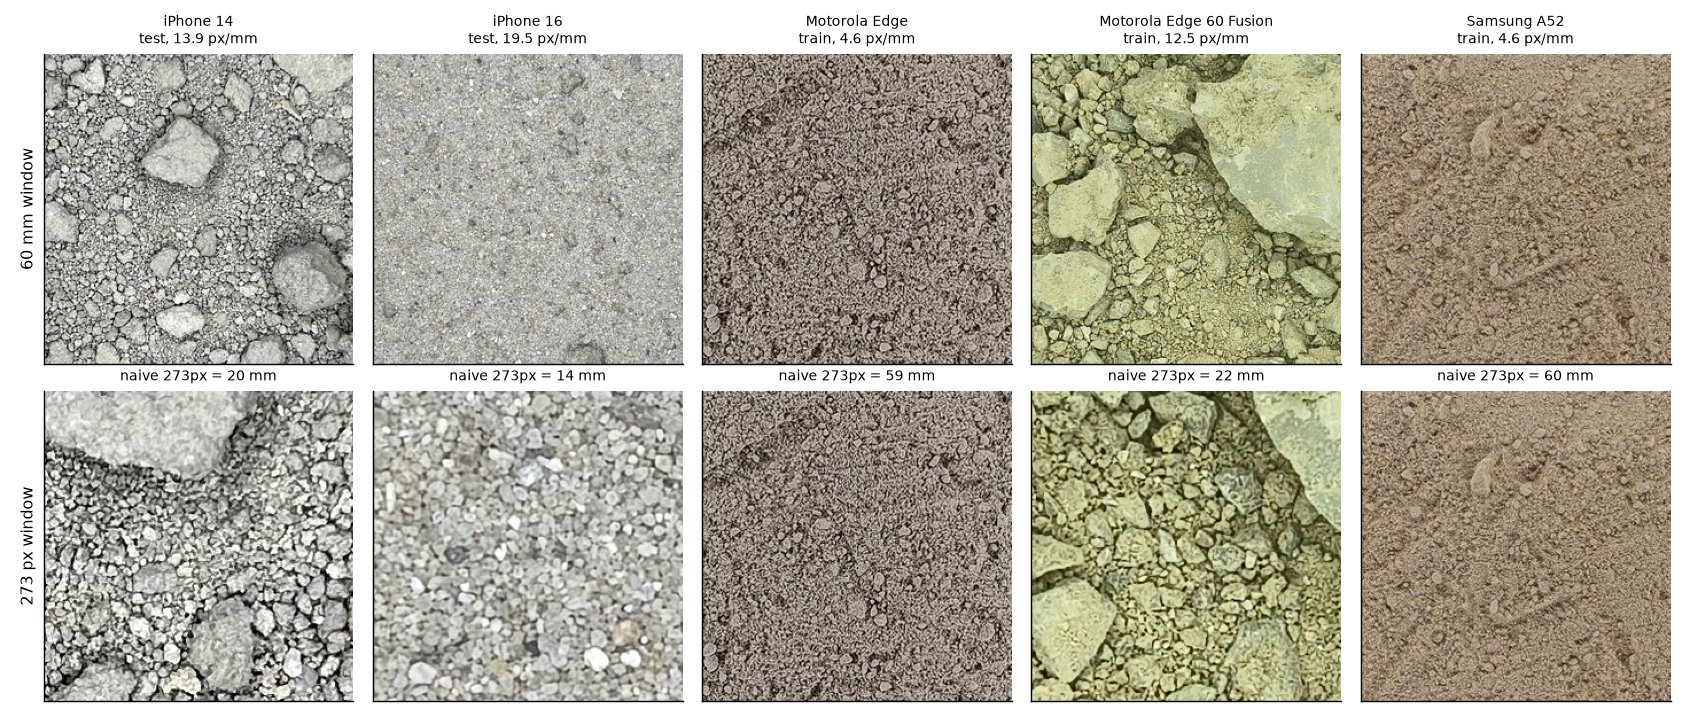

In [4]:
eda.plot_scale_sheet(index)
show(path=eda.OUT / "scale_sheet.png")

In [5]:
grains = [0.063, 0.2, 0.63, 2.0, 6.3, 20.0]
ppms = {"work scale (4.5 px/mm)": WORK_PPM, "train stored (~4.6)": 4.6,
        "test iPhone 14 (13.9)": 13.94, "test iPhone 16 (19.5)": 19.52, "Samsung native (26.3)": 26.33}
gp = pd.DataFrame({k: [g * v for g in grains] for k, v in ppms.items()}, index=[f"{g} mm" for g in grains]).T
print("Grain diameter in pixels (< 1 px = invisible as an individual grain, ~3 px = a few-pixel blob):")
display(gp.style.format("{:.1f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=6, axis=None))

Grain diameter in pixels (< 1 px = invisible as an individual grain, ~3 px = a few-pixel blob):


,0.063 mm,0.2 mm,0.63 mm,2.0 mm,6.3 mm,20.0 mm
work scale (4.5 px/mm),0.3,0.9,2.8,9.0,28.3,90.0
train stored (~4.6),0.3,0.9,2.9,9.2,29.0,92.0
test iPhone 14 (13.9),0.9,2.8,8.8,27.9,87.8,278.8
test iPhone 16 (19.5),1.2,3.9,12.3,39.0,123.0,390.4
Samsung native (26.3),1.7,5.3,16.6,52.7,165.9,526.6


## 4. Таргет
Три режими: **fine** (7, D50 < 0.063 мм), **sand** (6), **gravel** (11). Гравійні криві дуже схожі між собою, а fine/sand розкидані. Майже немає бімодальних ґрунтів, тож крива здебільшого визначається положенням і нахилом. Великі камені (> 20 мм) — максимум 24 % маси, тобто тайл 50 мм їх вміщує.

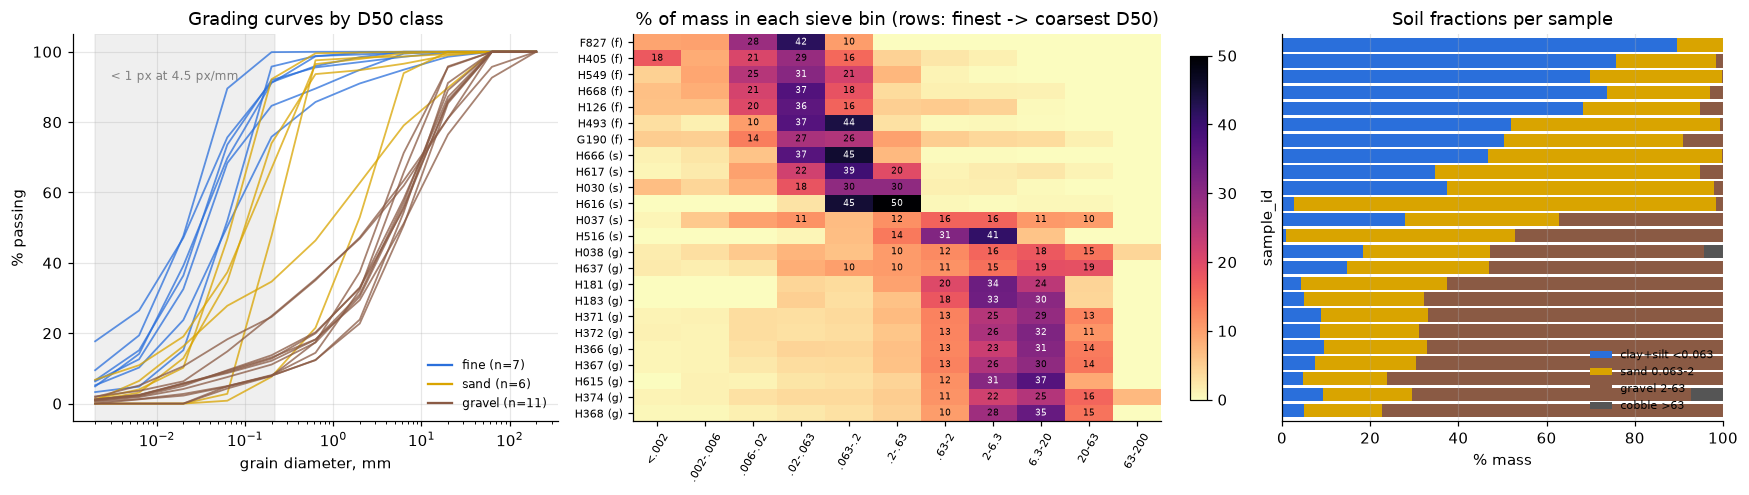

Bimodal-ish: samples with >=15% silt+clay AND >=15% gravel: 2 / 24
Median % of mass finer than 0.2 mm (below 1 px at work scale): 30%


,D50 mm,% <0.063 (silt+clay),% <0.2 (sub-pixel),% >2 (gravel+),% >20
min,0.02,0.82,7.63,0.00,0.00
50%,1.30,16.55,29.78,42.17,2.79
max,6.13,89.56,99.90,77.24,23.51


In [6]:
y = Y.loc[ORDER].to_numpy()
bins = np.diff(y, prepend=0.0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1.3, 1]})
for sid in ORDER:
    axes[0].plot(SIEVES_MM, Y.loc[sid], color=CLASS_COLORS[cls[sid]], alpha=0.75, lw=1.2)
for c, col in CLASS_COLORS.items():
    axes[0].plot([], [], color=col, label=f"{c} (n={(cls == c).sum()})")
axes[0].set(xscale="log", xlabel="grain diameter, mm", ylabel="% passing", title="Grading curves by D50 class")
axes[0].axvspan(0.002, 0.22, color="grey", alpha=0.12)
axes[0].text(0.003, 92, "< 1 px at 4.5 px/mm", fontsize=8, color="grey")
axes[0].legend(frameon=False, fontsize=8)

im = axes[1].imshow(bins, aspect="auto", cmap="magma_r", vmin=0, vmax=50)
axes[1].set_yticks(range(len(ORDER)), [f"{s} ({cls[s][0]})" for s in ORDER], fontsize=7)
edges = ["<.002", ".002-.006", ".006-.02", ".02-.063", ".063-.2", ".2-.63", ".63-2", "2-6.3", "6.3-20", "20-63", "63-200"]
axes[1].set_xticks(range(11), edges, rotation=60, fontsize=7)
axes[1].set_title("% of mass in each sieve bin (rows: finest -> coarsest D50)")
axes[1].grid(False)
for (r, c), v in np.ndenumerate(bins):
    if v >= 10:
        axes[1].text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=6, color="white" if v > 30 else "black")
plt.colorbar(im, ax=axes[1], fraction=0.03)

frac = pd.DataFrame({"clay+silt <0.063": y[:, 3], "sand 0.063-2": y[:, 6] - y[:, 3],
                     "gravel 2-63": y[:, 9] - y[:, 6], "cobble >63": 100 - y[:, 9]}, index=ORDER)
frac.plot.barh(stacked=True, ax=axes[2], width=0.85, color=["#2a6fdb", "#d9a400", "#8a5a44", "#555"])
axes[2].invert_yaxis(); axes[2].set_yticks([]); axes[2].set_xlabel("% mass"); axes[2].legend(fontsize=7, frameon=False, loc="lower right")
axes[2].set_title("Soil fractions per sample")
plt.tight_layout(); plt.show()

summ = pd.DataFrame({"D50 mm": D50, "class": cls, "% <0.063 (silt+clay)": Y["0.063"],
                     "% <0.2 (sub-pixel)": Y["0.2"], "% >2 (gravel+)": 100 - Y["2"], "% >20": 100 - Y["20"],
                     "family": fam}).loc[ORDER]
print(f"Bimodal-ish: samples with >=15% silt+clay AND >=15% gravel: "
      f"{int(((summ['% <0.063 (silt+clay)'] >= 15) & (summ['% >2 (gravel+)'] >= 15)).sum())} / {len(summ)}")
print(f"Median % of mass finer than 0.2 mm (below 1 px at work scale): {summ['% <0.2 (sub-pixel)'].median():.0f}%")
summ.describe().loc[["min", "50%", "max"]]

Кожен train-зразок: crop 60 мм на робочому масштабі над його міткою. Дрібні ґрунти не виглядають «гладкими»: висушена глина/пил збивається в грудки розміром 1–5 мм, схожі на пісок.

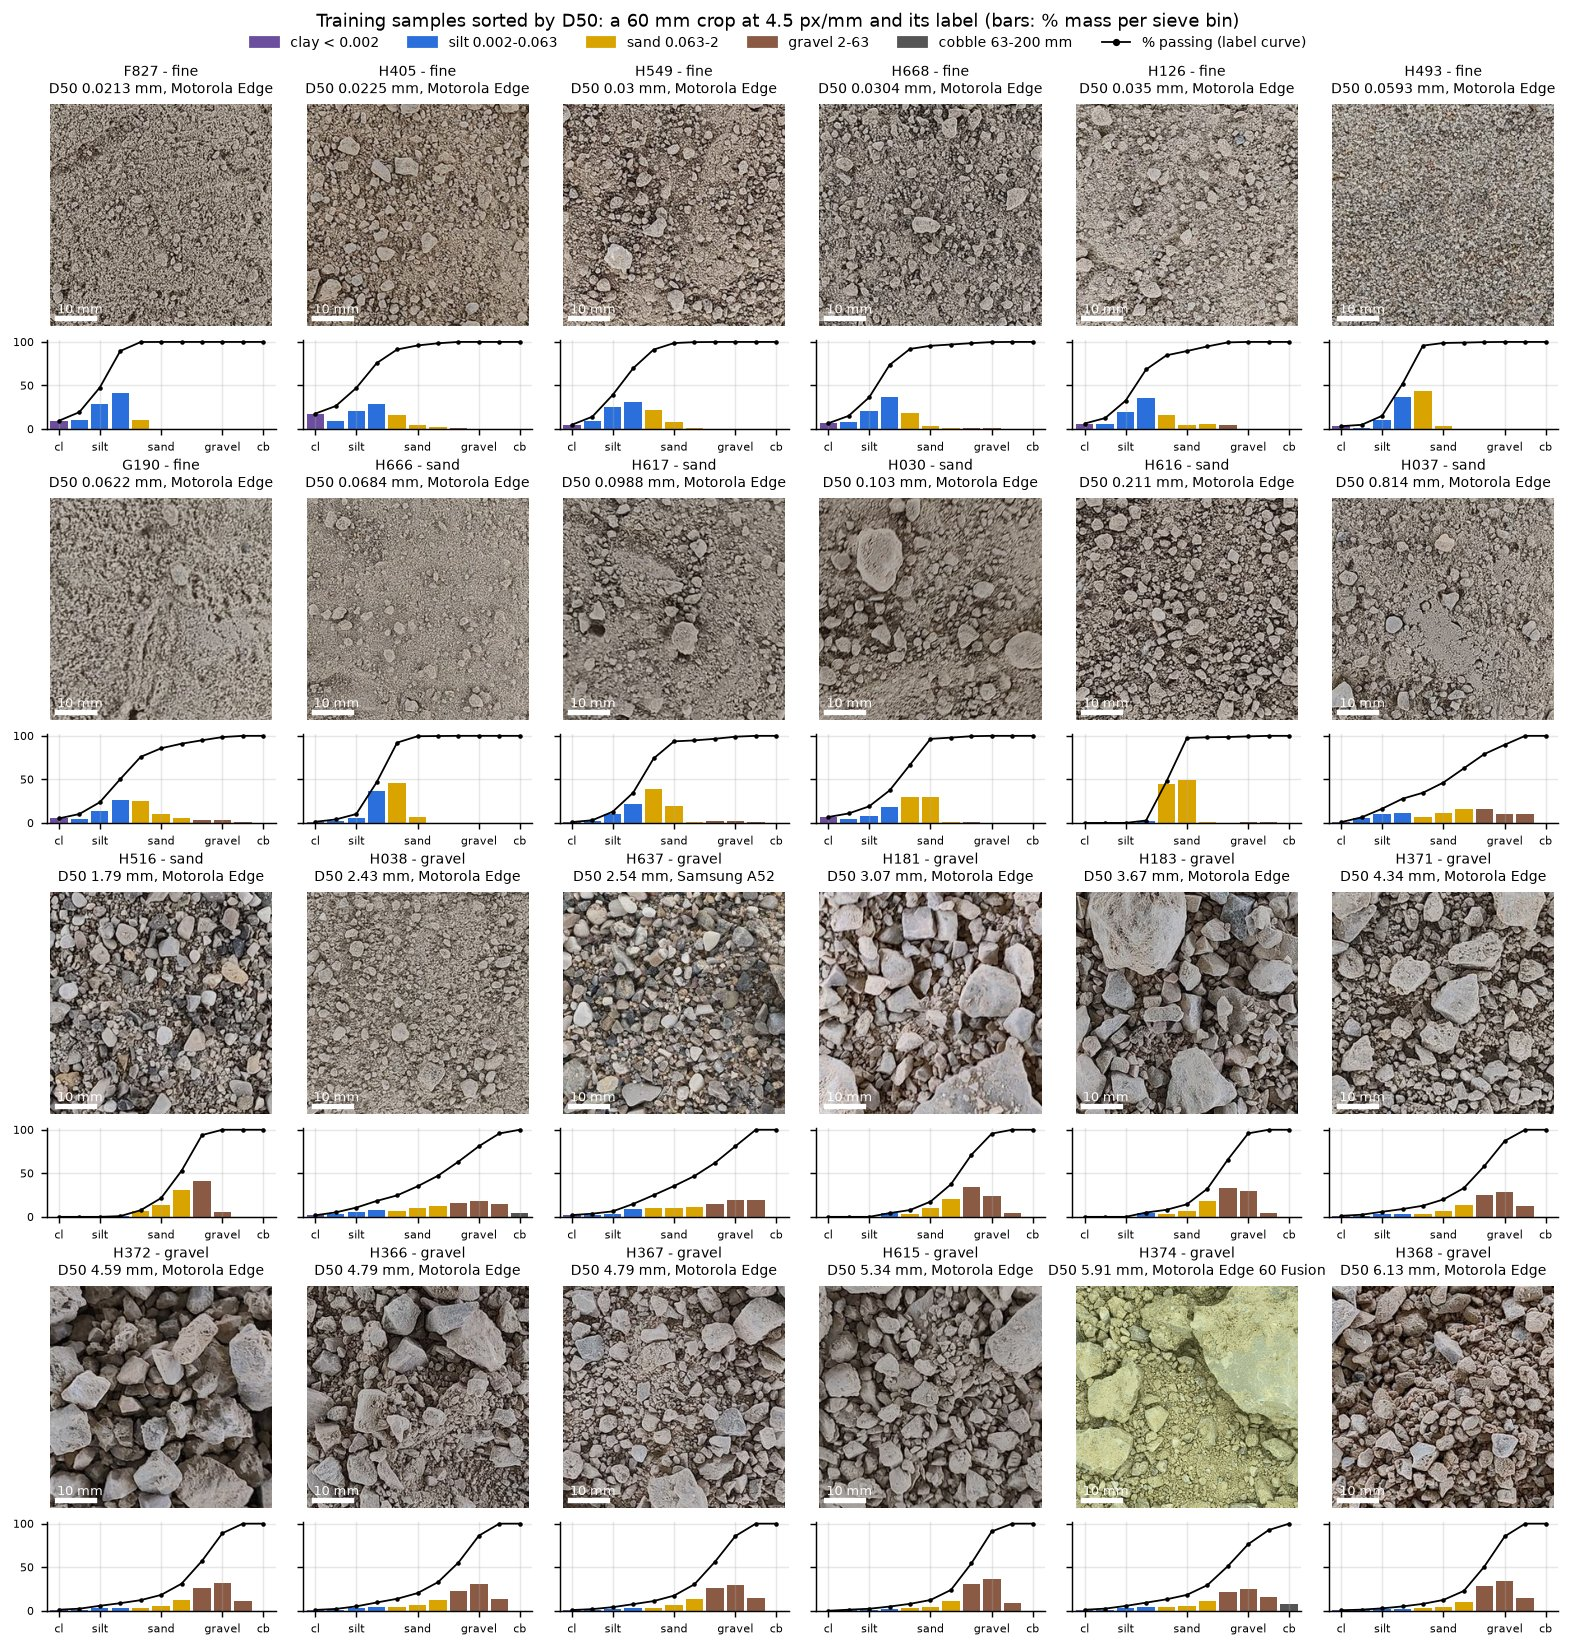

In [7]:
eda.plot_soil_grid(index, labels, labels["sample_id"].map(cls))
show(path=eda.OUT / "soil_grid.png")

## 5. Де живе метрика
Ліворуч — внесок кожного інтервалу сит в EMD середньої кривої: найбільше важать 0.063–6.3 мм, тобто межа між «видно» і «не видно». Праворуч — ціна чистої помилки масштабу: ≈ 100·|log10 f|, тож 2× ≈ 30 EMD, а 4× ≈ 60.

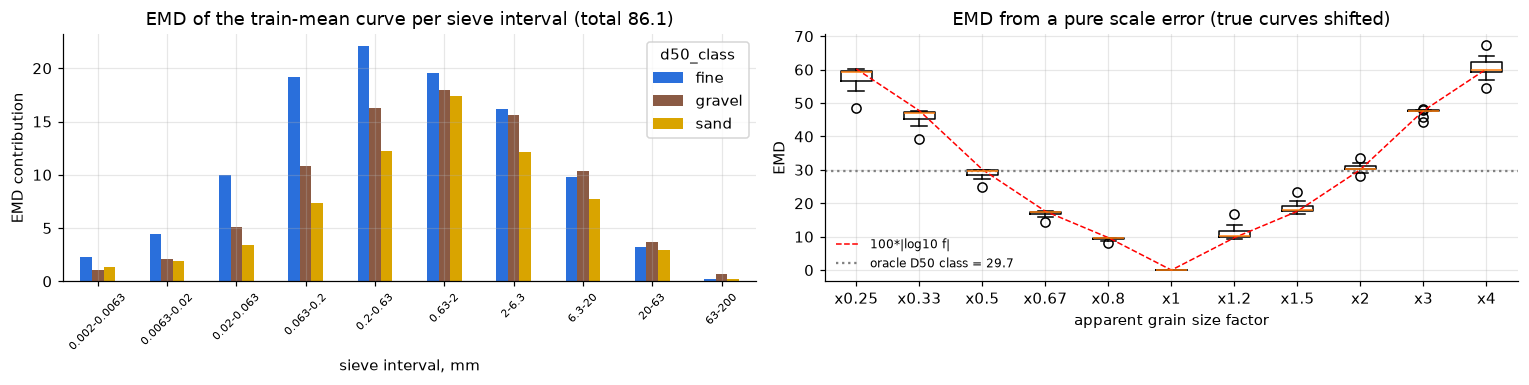

Train-mean curve: fine part (<0.2 mm) 22.7 + coarse part 63.5 = 86.1


In [8]:
mean_pred = np.tile(Y.mean().to_numpy(), (len(Y), 1))
err = np.abs(Y.to_numpy()[:, :-1] - mean_pred[:, :-1]) * LOG_WIDTHS
contrib = pd.DataFrame(err, index=Y.index, columns=[f"{a}-{b}" for a, b in zip(TARGET_COLS[:-1], TARGET_COLS[1:])])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
contrib.groupby(cls).mean().T.plot.bar(ax=axes[0], color=[CLASS_COLORS[c] for c in contrib.groupby(cls).mean().index])
axes[0].set(title=f"EMD of the train-mean curve per sieve interval (total {err.sum(1).mean():.1f})",
            ylabel="EMD contribution", xlabel="sieve interval, mm")
axes[0].tick_params(axis="x", rotation=45, labelsize=7)
f = [1 / 4, 1 / 3, 1 / 2, 1 / 1.5, 1 / 1.25, 1, 1.25, 1.5, 2, 3, 4]
from soilgsd.metric import shift_curve
cost = [emd_per_sample(Y.to_numpy(), shift_curve(Y.to_numpy(), k)) for k in f]
axes[1].boxplot(cost, tick_labels=[f"x{k:.2g}" for k in f])
axes[1].plot(range(1, len(f) + 1), [100 * abs(np.log10(k)) for k in f], "r--", lw=1, label="100*|log10 f|")
axes[1].axhline(29.7, color="grey", ls=":", label="oracle D50 class = 29.7")
axes[1].set(title="EMD from a pure scale error (true curves shifted)", ylabel="EMD", xlabel="apparent grain size factor")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
fine, coarse = emd_parts(Y.to_numpy(), mean_pred)
print(f"Train-mean curve: fine part (<0.2 mm) {fine.mean():.1f} + coarse part {coarse.mean():.1f} = {(fine + coarse).mean():.1f}")

Еталони без зображень на спільних фолдах: середня крива 89.5; **оракул, який знає лише клас D50 → 29.7**. Отже, правильно визначити fine/sand/gravel — це більша частина задачі.

In [9]:
eda.cv_constant_baselines(labels, folds, labels["sample_id"].map(cls))

,CV EMD mean,std over repeats,D50 |log10 err|
uniform (Kaggle baseline),102.02,0.00,0.91
train mean,89.52,0.99,0.98
train median,95.47,3.10,1.05
oracle D50 class -> class median,29.71,0.00,0.26


## 6. Групи і фолди
Червоні клітинки — пари кривих ближчі за 10 EMD (ймовірно, той самий об'єкт: H366/H367/H371/H372). Такі пари в `data/folds.csv` ніколи не розділяються між train і val. Праворуч видно: у гравію сусід завжди ближче 15 EMD (легко «вгадати сусідом»), а в sand/fine — 20–40 EMD, тобто для них у train немає схожих прикладів.

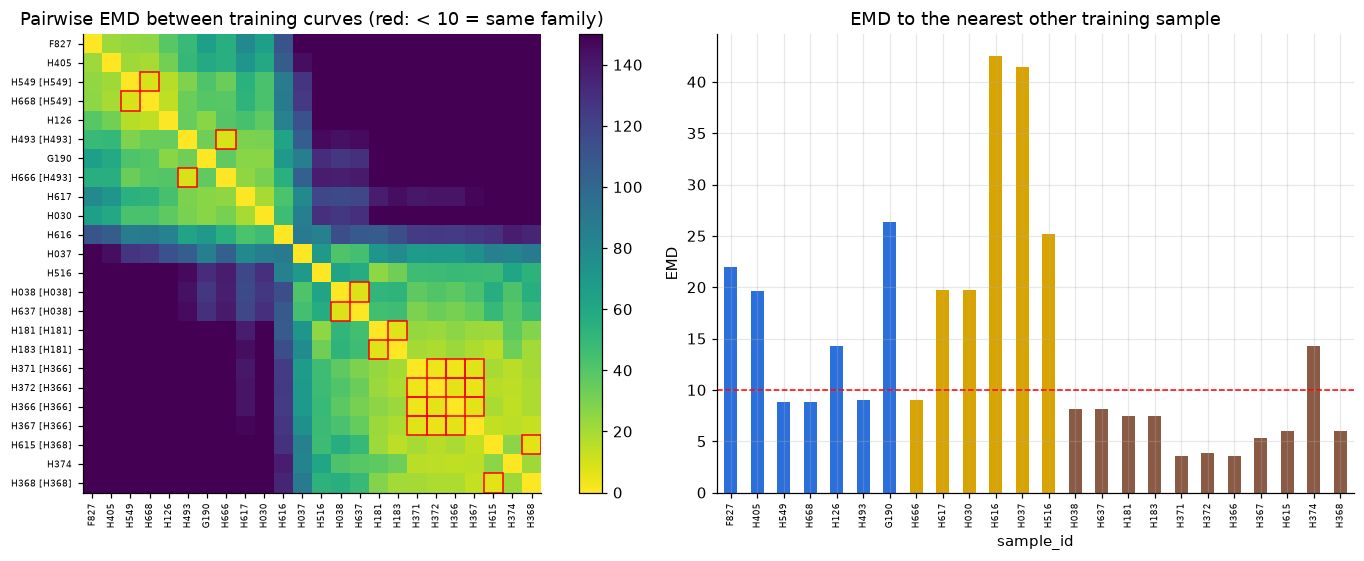

fold,0,1,2,3,4,5
repeat 0,,,,,,
fine,1,2,1,1,1,1
gravel,4,1,2,2,2,0
sand,1,1,1,1,1,1
samples,6,4,4,4,4,2
families,3,3,3,3,2,2


families: 16 for 24 samples; multi-sample families: {'H038': ['H038', 'H637'], 'H181': ['H181', 'H183'], 'H366': ['H366', 'H367', 'H371', 'H372'], 'H368': ['H368', 'H615'], 'H493': ['H493', 'H666'], 'H549': ['H549', 'H668']}


In [10]:
yo = Y.loc[ORDER].to_numpy()
dist = np.array([emd_per_sample(np.repeat(a[None], len(yo), 0), yo) for a in yo])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(dist, cmap="viridis_r", vmax=150)
lab = [f"{s} [{fam[s]}]" if (fam == fam[s]).sum() > 1 else s for s in ORDER]
axes[0].set_xticks(range(len(ORDER)), ORDER, rotation=90, fontsize=6)
axes[0].set_yticks(range(len(ORDER)), lab, fontsize=6)
for (r, c), v in np.ndenumerate(dist):
    if r != c and v < 10:
        axes[0].add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec="red", lw=1))
axes[0].set_title("Pairwise EMD between training curves (red: < 10 = same family)"); axes[0].grid(False)
plt.colorbar(im, ax=axes[0], fraction=0.04)
nn = pd.Series(np.where(np.eye(len(yo), dtype=bool), np.inf, dist).min(1), index=ORDER)
nn.plot.bar(ax=axes[1], color=[CLASS_COLORS[cls[s]] for s in ORDER])
axes[1].axhline(10, color="red", ls="--", lw=1)
axes[1].set(title="EMD to the nearest other training sample", ylabel="EMD")
axes[1].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()
f0 = folds[folds.repeat == 0]
display(f0.groupby(["fold", "d50_class"]).size().unstack(fill_value=0)
        .assign(samples=lambda d: d.sum(1), families=f0.groupby("fold").family.nunique()).T
        .rename_axis("repeat 0"))
print(f"families: {fam.nunique()} for {len(fam)} samples; multi-sample families:",
      {k: list(v) for k, v in fam.groupby(fam).groups.items() if len(v) > 1})

## 7. Що бачить модель: прості статистики тайлів
Тайли 50 мм на 4.5 px/mm (224 px; той самий кеш `data/cache/tiles`, що й для навчання). Для кожного тайла рахуємо колір (яскравість, насиченість, «червоність») і текстуру: контраст, градієнт, `fine_detail` (частка дрібних деталей ~0.7 мм), `coarse_structure` (частка великих структур ≥ 2.5 мм).

In [11]:
def tile_stats(t: np.ndarray) -> pd.DataFrame:
    """Cheap colour and texture statistics of 50 mm tiles at 4.5 px/mm (224 px)."""
    x = t.astype(np.float32) / 255
    g = x.mean(-1)
    mx, mn = x.max(-1), x.min(-1)
    sat = np.where(mx > 0, (mx - mn) / np.maximum(mx, 1e-6), 0)
    gy, gx = np.gradient(g, axis=(1, 2))
    fine_detail = g - uniform_filter(g, size=(1, 3, 3))           # ~0.7 mm scale
    coarse = gaussian_filter(g, sigma=(0, 11, 11))                 # ~2.5 mm blobs and larger (stones, shadows)
    return pd.DataFrame({
        "brightness": g.mean((1, 2)),
        "saturation": sat.mean((1, 2)),
        "redness": (x[..., 0] - x[..., 2]).mean((1, 2)),
        "contrast": g.std((1, 2)),
        "gradient": np.hypot(gx, gy).mean((1, 2)),
        "fine_detail": fine_detail.std((1, 2)) / (g.std((1, 2)) + 1e-6),
        "coarse_structure": coarse.std((1, 2)) / (g.std((1, 2)) + 1e-6),
    })

parts = []
for split in ["train", "test"]:
    tiles, meta = tile_cache(index, boxes, 50, WORK_PPM, split)  # cached in data/cache/tiles for training too
    st = pd.concat([tile_stats(tiles[i:i + 256]) for i in range(0, len(tiles), 256)], ignore_index=True)
    parts.append(pd.concat([meta, st], axis=1).assign(split=split))
    if split == "train":
        train_tiles, train_meta = tiles, meta
    else:
        test_tiles, test_meta = tiles, meta
T = pd.concat(parts, ignore_index=True).merge(index[["path", "device"]], on="path")
FEATS = ["brightness", "saturation", "redness", "contrast", "gradient", "fine_detail", "coarse_structure"]
tpp = T.groupby(["split", "device", "path"]).size().groupby(["split", "device"]).agg(["min", "median", "max", "sum"])
display(tpp.rename(columns={"sum": "tiles total"}).rename(columns=lambda c: c if c == "tiles total" else f"tiles/photo {c}"))
tps = T[T.split == "train"].groupby("sample_id").size()
print(f"train tiles per sample: min {tps.min()}, median {tps.median():.0f}, max {tps.max()}; all {len(tr_ := T[T.split == 'train'])} train tiles come from only {tps.size} soils")

tiles/photo min  tiles/photo median  \
split device                                                         
test  iPhone 14                             12                24.0   
      iPhone 16                             24                24.0   
train Motorola Edge                         21                21.0   
      Motorola Edge 60 Fusion               28                28.0   
      Samsung A52                           35                35.0   

                               tiles/photo max  tiles total  
split device                                                 
test  iPhone 14                             24          324  
      iPhone 16                             24          504  
train Motorola Edge                         21         1449  
      Motorola Edge 60 Fusion               28           84  
      Samsung A52                           35         1925

train tiles per sample: min 84, median 147, max 238; all 3458 train tiles come from only 24 soils


## 8. Доменний зсув між телефонами
Зверху — розподіл по фото для кожного девайсу; знизу — **той самий зразок** на двох train-телефонах. Samsung стабільно розмитіший і кольоровіший за Motorola. Test (iPhone) майже сірий, а iPhone 16 різкіший за весь train. Для CNN звідси випливає: колір можна використовувати лише з сильною колір-аугментацією або взагалі без нього (grayscale); різкість теж треба вирівнювати, бо модель, що навчилась «розмито = дрібний ґрунт», на різкому iPhone 16 зсуне прогноз.

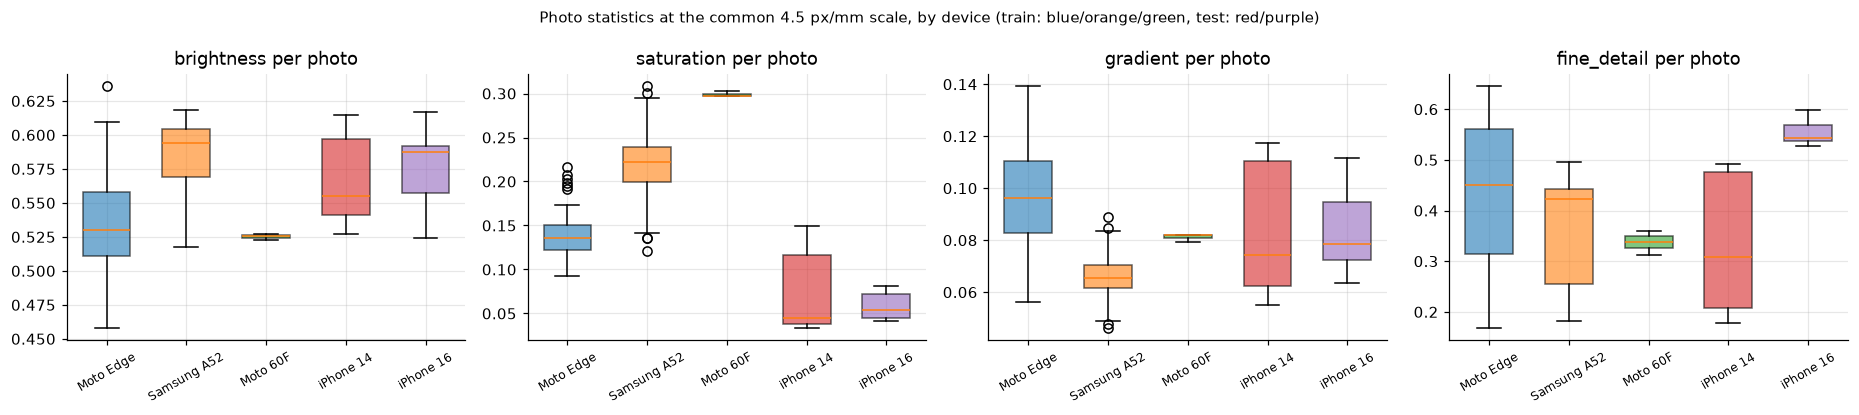

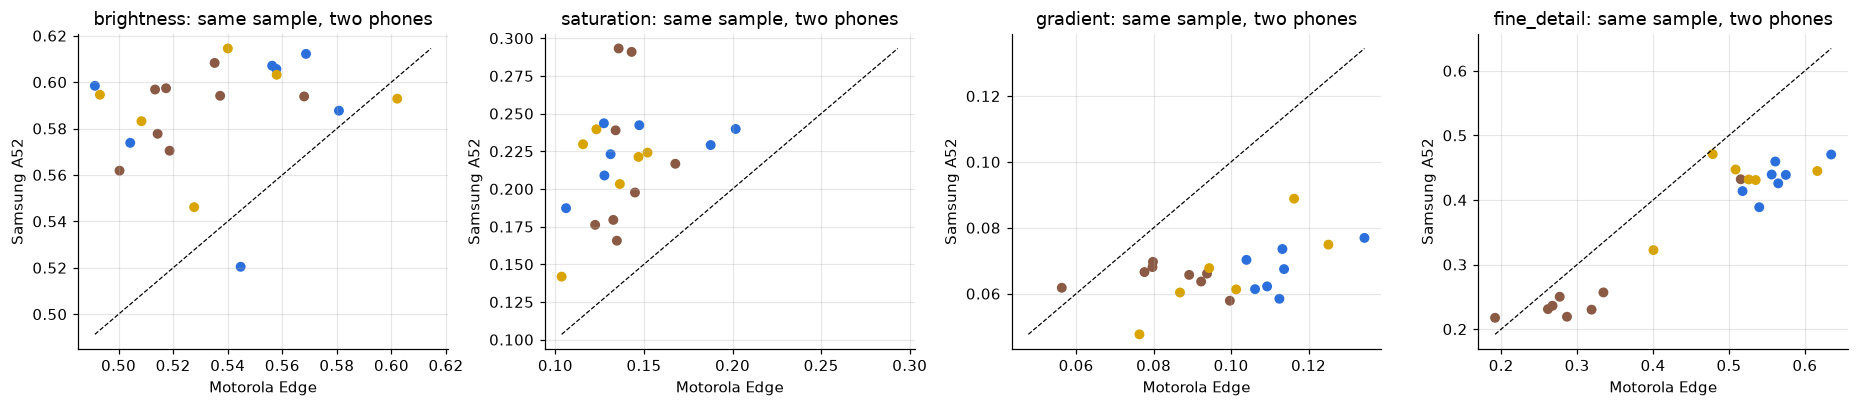

Samsung / Motorola, median over the same samples: {'brightness': 1.1100000143051147, 'saturation': 1.5099999904632568, 'redness': 1.9900000095367432, 'contrast': 0.7900000214576721, 'gradient': 0.6800000071525574, 'fine_detail': 0.800000011920929, 'coarse_structure': 1.399999976158142}


In [12]:
P = T.groupby(["split", "device", "sample_id", "path"])[FEATS].mean().reset_index()
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, f in zip(axes, ["brightness", "saturation", "gradient", "fine_detail"]):
    devs = list(DEV_COLORS)
    data = [P.loc[P.device == d, f] for d in devs]
    bp = ax.boxplot(data, tick_labels=[d.replace("Motorola Edge 60 Fusion", "Moto 60F").replace("Motorola Edge", "Moto Edge")
                                  for d in devs], patch_artist=True, widths=0.6)
    for patch, d in zip(bp["boxes"], devs):
        patch.set_facecolor(DEV_COLORS[d]); patch.set_alpha(0.6)
    ax.set_title(f"{f} per photo"); ax.tick_params(axis="x", rotation=30, labelsize=8)
plt.suptitle("Photo statistics at the common 4.5 px/mm scale, by device (train: blue/orange/green, test: red/purple)", fontsize=10)
plt.tight_layout(); plt.show()

pair = P[P.split == "train"].groupby(["sample_id", "device"])[FEATS].mean().unstack("device")
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, f in zip(axes, ["brightness", "saturation", "gradient", "fine_detail"]):
    a, b = pair[(f, "Motorola Edge")], pair[(f, "Samsung A52")]
    ok = a.notna() & b.notna()
    ax.scatter(a[ok], b[ok], c=[CLASS_COLORS[cls[s]] for s in a[ok].index], s=30)
    lo, hi = min(a[ok].min(), b[ok].min()), max(a[ok].max(), b[ok].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    ax.set(xlabel="Motorola Edge", ylabel="Samsung A52", title=f"{f}: same sample, two phones")
plt.tight_layout(); plt.show()
ratio = (pair.xs("Samsung A52", axis=1, level=1) / pair.xs("Motorola Edge", axis=1, level=1)).median()
print("Samsung / Motorola, median over the same samples:", ratio.round(2).to_dict())

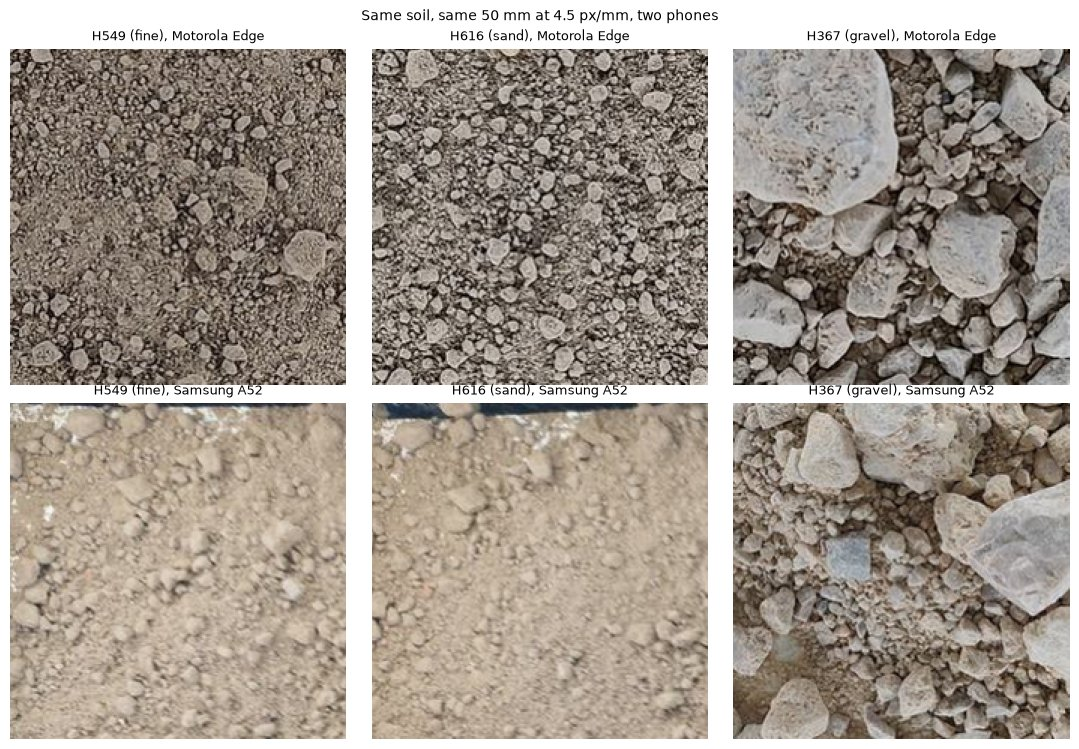

In [13]:
sid_pairs = pair[[("brightness", "Motorola Edge"), ("brightness", "Samsung A52")]].dropna().index
sid = [s for s in ORDER if s in sid_pairs]
shown = [sid[2], sid[len(sid) // 2], sid[-3]]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.6))
for j, s in enumerate(shown):
    for i, dev in enumerate(["Motorola Edge", "Samsung A52"]):
        p = train_meta.index[(train_meta.sample_id == s) & train_meta.path.str.contains(dev.split()[0])]
        axes[i, j].imshow(train_tiles[p[len(p) // 2]])
        axes[i, j].set_title(f"{s} ({cls[s]}), {dev}", fontsize=9); axes[i, j].axis("off")
plt.suptitle("Same soil, same 50 mm at 4.5 px/mm, two phones", fontsize=10)
plt.tight_layout(); show(fig, width=800)

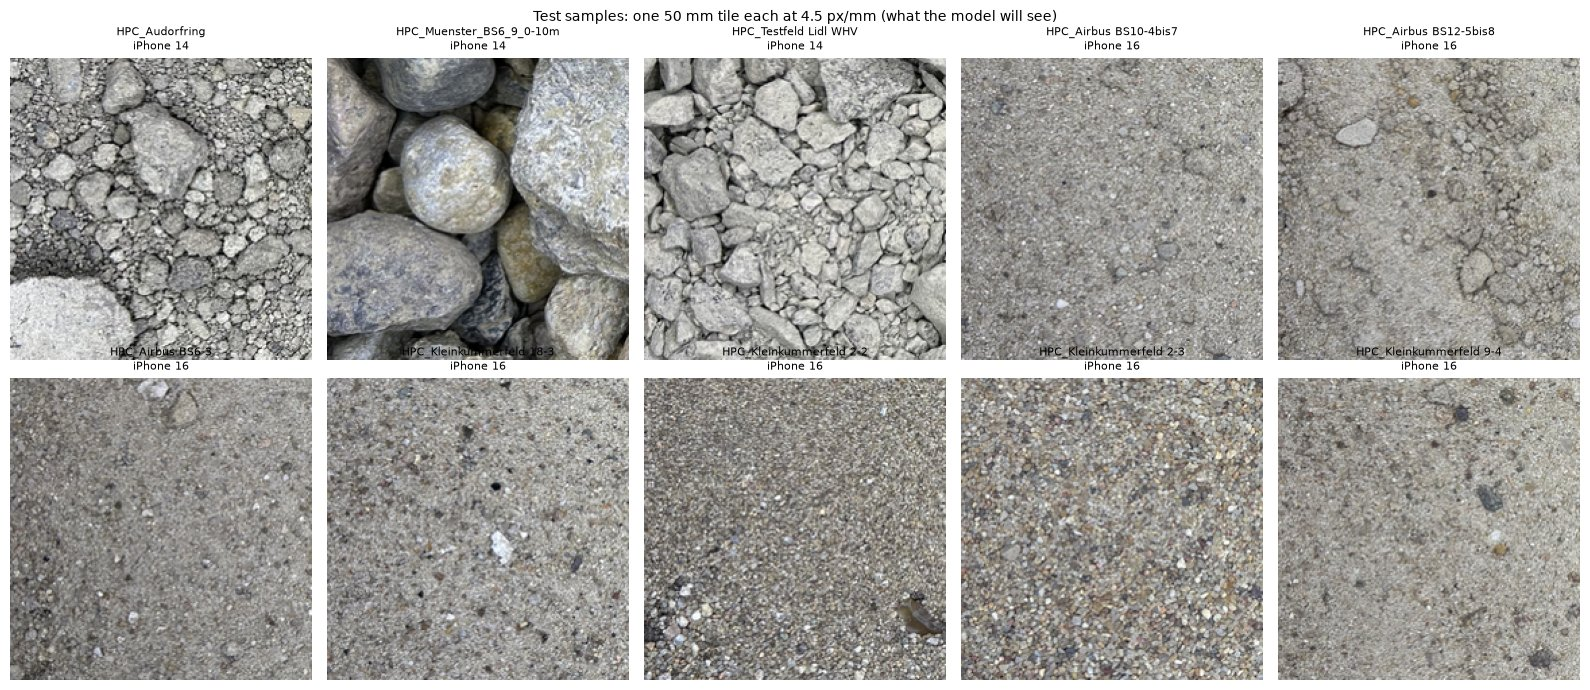

In [14]:
test_samples = index[index.split == "test"].groupby("sample_id").head(1)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, r) in zip(axes.ravel(), test_samples.iterrows()):
    p = test_meta.index[test_meta.path == r["path"]]
    ax.imshow(test_tiles[p[len(p) // 2]]); ax.axis("off")
    ax.set_title(f"{r['sample_id'][:28]}\n{r['device']}", fontsize=8)
plt.suptitle("Test samples: one 50 mm tile each at 4.5 px/mm (what the model will see)", fontsize=10)
plt.tight_layout(); show(fig, width=1100)

## 9. Звідки варіація
Частка дисперсії тайлів між зразками (сигнал), між фото одного зразка (девайс/перемішування) і між тайлами одного фото. Колір (redness, saturation) змінюється здебільшого **між фото одного зразка**, тобто через девайс, а не через ґрунт. Контраст і `fine_detail` змінюються переважно між зразками, тож вони несуть корисний сигнал. Яскравість і `coarse_structure` здебільшого шумлять від тайла до тайла, тому одного тайла мало, і агрегація по тайлах обов'язкова.

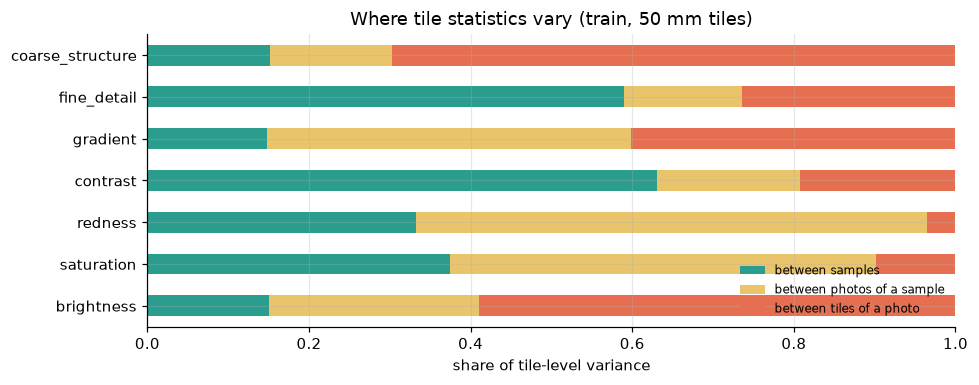

In [15]:
tr = T[T.split == "train"]
rows = {}
for f in FEATS:
    v_total = tr[f].var()
    sample_mean = tr.groupby("sample_id")[f].transform("mean")
    photo_mean = tr.groupby("path")[f].transform("mean")
    rows[f] = {"between samples": (sample_mean.var()) / v_total,
               "between photos of a sample": ((photo_mean - sample_mean).var()) / v_total,
               "between tiles of a photo": ((tr[f] - photo_mean).var()) / v_total}
vd = pd.DataFrame(rows).T
ax = vd.plot.barh(stacked=True, figsize=(9, 3.6), color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.set(xlabel="share of tile-level variance", title="Where tile statistics vary (train, 50 mm tiles)")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 10. Скільки сигналу в простих ознаках
Спірмен на рівні зразка (n = 24): `fine_detail` (−0.82), контраст (+0.71) і `coarse_structure` (+0.65) добре впорядковують D50. Але вони чітко розділяють лише gravel vs решта; fine і sand на графіках перемішані. Нижче — ridge на середніх по зразку статистиках на тих самих фолдах: текстура сама по собі дає ≈ рівень наявних CNN. Це планка, яку CNN у Part 1 має чесно перевищити.

,log10 D50,% <0.063,% 0.063-2 (sand),% >2 (gravel)
brightness,-0.42,+0.37,+0.29,-0.44
saturation,-0.19,+0.33,-0.29,-0.13
redness,-0.36,+0.49,-0.11,-0.33
contrast,+0.71,-0.70,-0.39,+0.74
gradient,-0.23,+0.05,+0.11,-0.19
fine_detail,-0.82,+0.70,+0.42,-0.87
coarse_structure,+0.65,-0.37,-0.46,+0.66


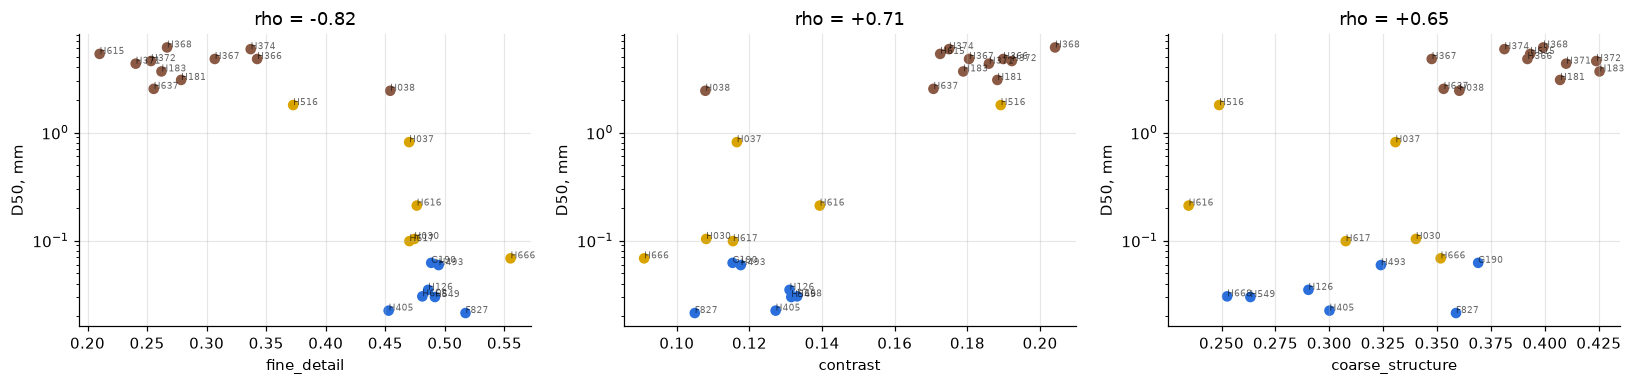

In [16]:
S = tr.groupby("sample_id")[FEATS].mean().loc[ORDER]
targets = {"log10 D50": np.log10(D50.loc[ORDER]), "% <0.063": Y.loc[ORDER, "0.063"],
           "% 0.063-2 (sand)": Y.loc[ORDER, "2"] - Y.loc[ORDER, "0.063"], "% >2 (gravel)": 100 - Y.loc[ORDER, "2"]}
rho = pd.DataFrame({t: {f: spearmanr(S[f], v).statistic for f in FEATS} for t, v in targets.items()})
display(rho.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1, axis=None)
        .set_caption("Spearman rho, sample-level (n=24); |rho| > 0.40 is p < 0.05"))
best = rho["log10 D50"].abs().sort_values(ascending=False).index[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, f in zip(axes, best):
    ax.scatter(S[f], D50.loc[ORDER], c=[CLASS_COLORS[cls[s]] for s in ORDER], s=35)
    for s in ORDER:
        ax.annotate(s, (S.loc[s, f], D50[s]), fontsize=6, alpha=0.6)
    ax.set(yscale="log", xlabel=f, ylabel="D50, mm", title=f"rho = {rho.loc[f, 'log10 D50']:+.2f}")
plt.tight_layout(); plt.show()

In [17]:
def cv_simple(feats: list[str]) -> tuple[float, float]:
    """Ridge on per-sample means of a few image statistics, scored on the shared folds."""
    Xs = tr.groupby("sample_id")[feats].mean()
    per_repeat = []
    for r in sorted(folds.repeat.unique()):
        yt_all, yp_all = [], []
        for _, tr_ids, va_ids in iter_folds(folds, r):
            m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))
            m.fit(Xs.loc[tr_ids], Y.loc[tr_ids])
            yp_all.append(repair_cummax(m.predict(Xs.loc[va_ids]))); yt_all.append(Y.loc[va_ids].to_numpy())
        per_repeat.append(emd_per_sample(np.concatenate(yt_all), np.concatenate(yp_all)).mean())
    return np.mean(per_repeat), np.std(per_repeat)

res = pd.DataFrame({name: cv_simple(f) for name, f in {
    "colour only (brightness, saturation, redness)": ["brightness", "saturation", "redness"],
    "texture only (contrast, gradient, fine, coarse)": ["contrast", "gradient", "fine_detail", "coarse_structure"],
    "all 7 statistics": FEATS}.items()}, index=["CV EMD", "std over repeats"]).T
res.loc["--- reference: train mean curve"] = [89.5, 1.0]
res.loc["--- reference: oracle D50 class"] = [29.7, 0.0]
res.loc["--- reference: best model so far (results.csv)"] = [pd.read_csv(resolve("reports/results.csv")).emd.min(), np.nan]
res.round(1)

,CV EMD,std over repeats
"colour only (brightness, saturation, redness)",59.9,1.6
"texture only (contrast, gradient, fine, coarse)",44.0,1.4
all 7 statistics,46.0,0.9
--- reference: train mean curve,89.5,1.0
--- reference: oracle D50 class,29.7,0.0
--- reference: best model so far (results.csv),37.7,NaN


## 11. Найважчі зразки (OOF усіх наявних експериментів)
Рядки — від найдрібнішого до найкрупнішого ґрунту. Гравій усі моделі передбачають добре, fine/sand — погано, і різні архітектури помиляються на тих самих зразках. Тобто вузьке місце — дані (агрегати замість зерен, відсутність схожих сусідів), а не вибір backbone. **H038** (гравій, але 18 % пилу) має ~115 EMD у всіх моделей, хоча його «близнюк» H637 — лише ~38: варто перевірити фото й мітку (нижче).

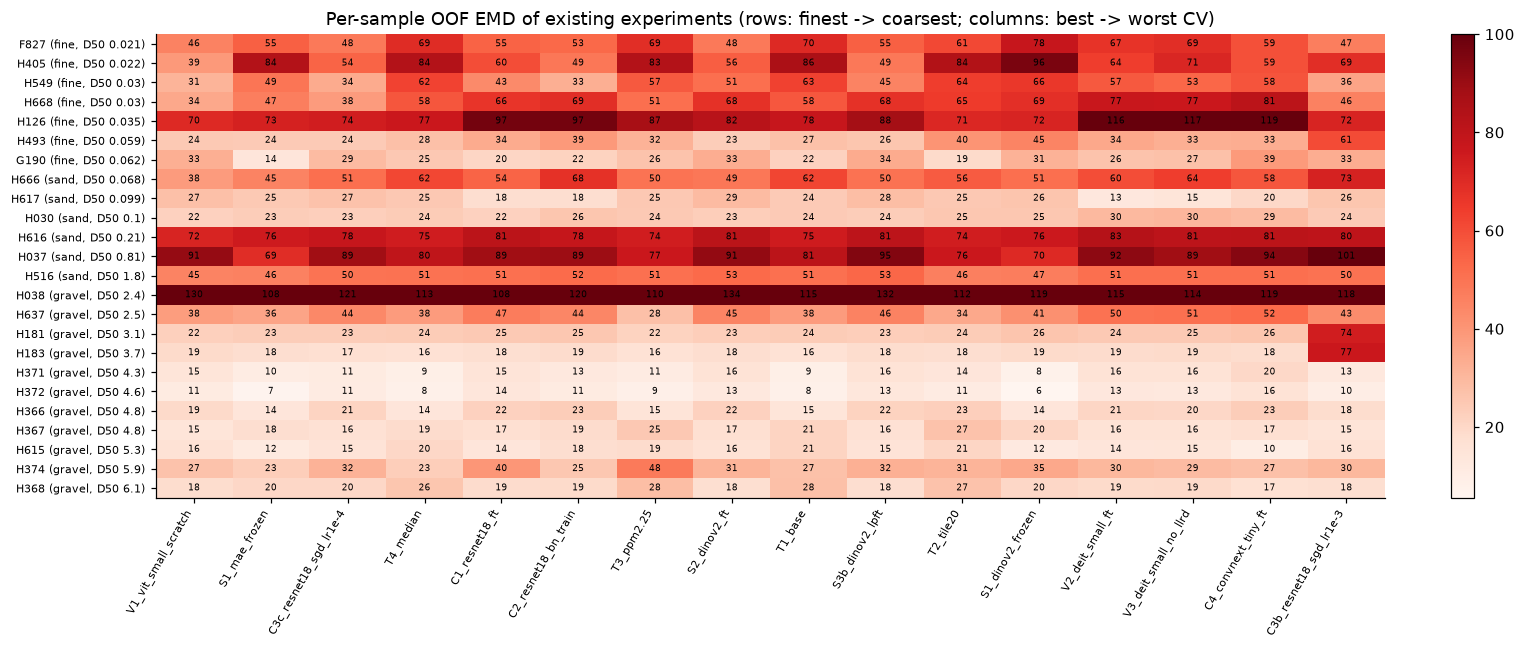

Correlation between models' per-sample errors (mean pairwise Pearson): 0.92


,mean EMD over models,class,D50,% <0.063,% >2,nearest-neighbour EMD
sample_id,,,,,,
H038,117.96,gravel,2.43,18.28,52.77,8.10
H126,86.94,fine,0.03,68.36,5.15,14.25
H037,85.87,sand,0.81,27.80,37.28,41.43
H616,77.91,sand,0.21,2.78,1.68,42.52
H405,67.86,fine,0.02,75.66,1.55,19.60
H668,60.65,fine,0.03,73.59,2.96,8.80
F827,59.34,fine,0.02,89.56,0.00,21.94
H666,55.71,sand,0.07,46.75,0.21,9.02


In [18]:
res_csv = pd.read_csv(resolve("reports/results.csv")).set_index("name")
exps = [e for e in res_csv.sort_values("emd").index if (resolve("outputs") / e / "oof.csv").exists() and res_csv.emd[e] < 60]
H = {}
for e in exps:
    oof = pd.read_csv(resolve(f"outputs/{e}/oof.csv"))
    H[e] = pd.Series(emd_per_sample(Y.loc[oof.sample_id].to_numpy(), oof[TARGET_COLS].to_numpy()),
                     index=oof.sample_id).groupby(level=0).mean()
H = pd.DataFrame(H).loc[ORDER]
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(H.to_numpy(), cmap="Reds", aspect="auto", vmax=100)
ax.set_xticks(range(len(H.columns)), H.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(H)), [f"{s} ({cls[s]}, D50 {D50[s]:.2g})" for s in H.index], fontsize=7)
for (r, c), v in np.ndenumerate(H.to_numpy()):
    ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=6)
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.02)
ax.set_title("Per-sample OOF EMD of existing experiments (rows: finest -> coarsest; columns: best -> worst CV)")
plt.tight_layout(); plt.show()
hard = pd.DataFrame({"mean EMD over models": H.mean(1), "class": cls, "D50": D50, "% <0.063": Y["0.063"],
                     "% >2": 100 - Y["2"], "nearest-neighbour EMD": nn}).loc[ORDER]
print(f"Correlation between models' per-sample errors (mean pairwise Pearson): "
      f"{H.corr().where(~np.eye(len(H.columns), dtype=bool)).stack().mean():.2f}")
hard.sort_values("mean EMD over models", ascending=False).head(8)

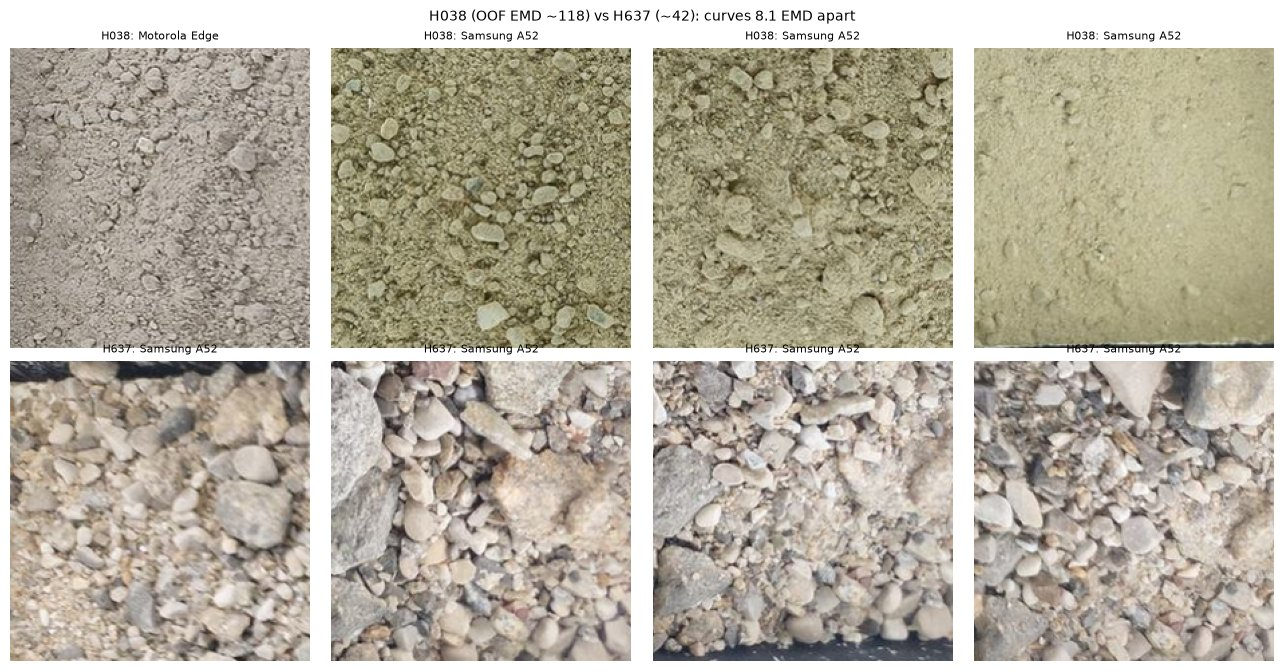

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for i, s in enumerate(["H038", "H637"]):
    p = train_meta.index[train_meta.sample_id == s]
    for j, k in enumerate(np.linspace(0, len(p) - 1, 4).astype(int)):
        axes[i, j].imshow(train_tiles[p[k]]); axes[i, j].axis("off")
        axes[i, j].set_title(f"{s}: {index.set_index('path').device[train_meta.path[p[k]]]}", fontsize=8)
fig.suptitle(f"H038 (OOF EMD ~{H.loc['H038'].mean():.0f}) vs H637 (~{H.loc['H637'].mean():.0f}): curves {dist[list(ORDER).index('H038'), list(ORDER).index('H637')]:.1f} EMD apart", fontsize=10)
plt.tight_layout(); show(fig, width=1000)

**H038:** на всіх фото — дрібний пилувато-піщаний ґрунт без помітного гравію, тоді як H637 з майже тією самою кривою (8 EMD) — явний гравій. Найімовірніше, фото й мітка H038 не відповідають одне одному, як колись було з H374. Сам цей зразок додає ≈ 4 EMD до середнього CV (115 / 24 ≈ 4.8 проти ~20 для типового гравію).

## Що з цього взяти в Part 1
- Вхід: спільні 4.5 px/mm, тайл 50 мм, тільки soil box; **жодних scale-аугментацій** (RandomResizedCrop, zoom).
- Колір: сильний colour jitter / grayscale як абляція; різкість: легкий blur/sharpen або JPEG-аугментація як гіпотеза для перенесення на iPhone.
- BatchNorm: у батчі тайли кількох ґрунтів від 2 девайсів, статистики різні → заморожений BN або GroupNorm.
- H038: звітувати CV з ним і без нього (не видаляти мовчки).
- Оцінка: окремо EMD на fine/sand/gravel; планки — 44 (текстура + ridge) і 29.7 (оракул класу).